In [1]:
import numpy as np
import pandas as pd
from utils import precision_recall_by_bin, IV, plot_woe_iv
import matplotlib.pyplot as plt

In [2]:
import warnings

warnings.filterwarnings("ignore")

In [3]:
data = pd.read_csv('../Data/temp_training.csv')

In [4]:
def flag(series, condition):
    return condition.astype(float).where(series.notna())

def divide_positive(numerator, denominator):
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        ratio = numerator / denominator.where(denominator > 0)
    return ratio.replace([np.inf, -np.inf], np.nan)

def divide_all(numerator, denominator):
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        ratio = numerator / denominator
    return ratio.replace([np.inf, -np.inf], np.nan)

In [5]:
# 1. Size
features = data[['id','data_type','default']]
features["log_assets"] = np.log(data["asst_tot"].where(data["asst_tot"] > 0))

# 2. Profitability
features["net_profit_assets"] = divide_positive(data["profit"], data["asst_tot"])
features["operating_profit_assets"] = divide_positive(data["prof_operations"], data["asst_tot"])
features["operating_margin"] = divide_positive(data["prof_operations"], data["rev_operating"])

# 3. Liquidity
features["working_capital_assets"] = divide_positive(data["wc_net"], data["asst_tot"])
features["cash_assets"] = divide_positive(data["cash_and_equiv"], data["asst_tot"])
features["cash_short_term_debt"] = divide_positive(data["cash_and_equiv"], data["debt_st"])

# 4. Solvency and debt burden
data['liabilities_tot'] = data["asst_tot"] - data["eqty_tot"]

features["liabilities_assets_proxy"] = divide_positive(data['liabilities_tot'], data["asst_tot"])
features["equity_assets"] = divide_positive(data["eqty_tot"], data["asst_tot"])
features["short_term_debt_assets"] = divide_positive(data["debt_st"], data["asst_tot"])

# 5. Debt-service capacity
features["interest_coverage_proxy"] = divide_positive(data["prof_operations"], data["exp_financing"])

# 6. Cash generation
features["operating_cashflow_assets"] = divide_positive(data["cf_operations"], data["asst_tot"])
features["cashflow_liabilities_proxy"] = divide_positive(data["cf_operations"], data['liabilities_tot'])
features["cashflow_profit_gap_assets"] = divide_positive(data["profit"] - data["cf_operations"], data["asst_tot"])

# 7. Activity and receivables
features["sales_assets"] = divide_positive(data["rev_operating"], data["asst_tot"])
features["receivables_assets"] = divide_positive(data["AR"], data["asst_tot"])
features["receivables_days_proxy"] = 365 * divide_positive(data["AR"].where(data["AR"] >= 0), data["rev_operating"])

# 8. Distress and special-state indicators
features["negative_equity"] = flag(data["eqty_tot"], data["eqty_tot"] < 0)
features["operating_loss"] = flag(data["prof_operations"], data["prof_operations"] < 0)
features["nonpositive_revenue"] = flag(data["rev_operating"], data["rev_operating"] <= 0)
features["zero_financing_expense"] = flag(data["exp_financing"], data["exp_financing"] == 0)

# 9. Business context
features["sector_category"] = data["ateco_sector"]#.astype("string")
features["legal_structure_category"] = data["legal_struct"].astype("string")

In [6]:
features.to_csv('../Data/ratio_and_flag_features.csv', index=False)

In [7]:
feature_cols = [f for f in features.columns if f not in ['id','data_type','default']]
iv_df = []
for f in feature_cols:
    try:
        iv_train, iv_train_df = IV(features.query('data_type == "train"'), f)
        iv_test, iv_test_df = IV(features.query('data_type == "test"'), f)
        iv_oot, iv_oot_df = IV(features.query('data_type == "oot"'), f)
        iv_df.append([f, iv_train, iv_train_df, iv_test, iv_test_df, iv_oot, iv_oot_df])
    except:
        print(f'FAILED: {f}')
iv_df = pd.DataFrame(iv_df, columns=['features','iv_train','iv_train_df','iv_test','iv_test_df','iv_oot','iv_oot_df'])
iv_df.to_csv('../Files/iv_df.csv', index=False)

FAILED: legal_structure_category


In [8]:
least_important_features = iv_df.query('iv_train <= 0.02').sort_values('iv_train', ascending=False)
display(least_important_features)
suspicious_features = iv_df.query('iv_train >= 0.5').sort_values('iv_train', ascending=False)
display(suspicious_features)

,features,iv_train,iv_train_df,iv_test,iv_test_df,iv_oot,iv_oot_df
0,log_assets,7.146279e-03,bins Goods Bads Goods (%) B...,1.272813e-02,bins Goods Bads Goods (%) B...,1.066011e-02,bins Goods Bads Goods (%) B...
18,operating_loss,1.286662e-04,bins Goods Bads Goods (%) Bad...,1.096944e-11,bins Goods Bads Goods (%) Bad...,5.486114e-06,bins Goods Bads Goods (%) Bad...
19,nonpositive_revenue,2.630087e-05,bins Goods Bads Goods (%) Bad...,1.710884e-03,bins Goods Bads Goods (%) Bad...,1.502038e-05,bins Goods Bads Goods (%) Bad...
20,zero_financing_expense,1.641188e-07,bins Goods Bads Goods (%) Bad...,2.149781e-03,bins Goods Bads Goods (%) Bad...,2.696748e-05,bins Goods Bads Goods (%) Bad...
17,negative_equity,2.197584e-12,bins Goods Bads Goods (%) Bad...,1.096944e-11,bins Goods Bads Goods (%) Bad...,1.501506e-07,bins Goods Bads Goods (%) Bad...


,features,iv_train,iv_train_df,iv_test,iv_test_df,iv_oot,iv_oot_df
12,cashflow_liabilities_proxy,0.820941,bins Goods Bads Goods (%...,0.765317,bins Goods Bads Goods (...,0.928617,bins Goods Bads Goods (...
1,net_profit_assets,0.778038,bins Goods Bads Goods (...,0.690399,bins Goods Bads Goods (...,0.879966,bins Goods Bads Goods (...
11,operating_cashflow_assets,0.774725,bins Goods Bads Goods (%...,0.702807,bins Goods Bads Goods (%...,0.867200,bins Goods Bad...
7,liabilities_assets_proxy,0.621242,bins Goods Bads Goods (%) Ba...,0.589158,bins Goods Bads Goods (%) Ba...,0.694918,bins Goods Bads Goods (%) B...
8,equity_assets,0.621241,bins Goods Bads Goods (%) ...,0.589156,bins Goods Bads ...,0.694914,bins Goods Bads Goods (%) ...
2,operating_profit_assets,0.615308,bins Goods Bads Goods (...,0.542416,bins Goods Bads ...,0.669622,bins Goods Bads Goods (%...
10,interest_coverage_proxy,0.555554,bins Goods Bads Goods...,0.497379,bins Goods Bads Goods...,0.647202,bins Goods Bads Goods ...
3,operating_margin,0.507098,bins Goods Bads Goods...,0.466282,bins Goods Bads...,0.586435,bins Goods Bads Goods...


In [9]:
display(least_important_features.query('features == "log_assets"').loc[:, ['features', 'iv_train', 'iv_test', 'iv_oot']])
display(least_important_features.query('features == "log_assets"')['iv_train_df'][0])
display(precision_recall_by_bin(features.query('data_type == "train"'), 'log_assets'))

,features,iv_train,iv_test,iv_oot
0,log_assets,0.007146,0.012728,0.01066


,bins,Goods,Bads,Goods (%),Bads (%),WoE,IV_bin
0,"(14.22, 14.361]",46749,790,0.099734,0.118798,-0.174927,0.003335
1,"(14.361, 14.51]",46859,680,0.099968,0.102257,-0.022638,0.000052
2,"(14.51, 14.672]",46856,683,0.099962,0.102708,-0.027104,0.000074
3,"(14.672, 14.85]",46845,694,0.099938,0.104362,-0.043316,0.000192
4,"(14.85, 15.052]",46863,676,0.099977,0.101656,-0.016653,0.000028
5,"(15.052, 15.286]",46900,638,0.100056,0.095941,0.041990,0.000173
6,"(15.286, 15.576]",46895,644,0.100045,0.096844,0.032523,0.000104
7,"(15.576, 15.963]",46888,651,0.100030,0.097896,0.021563,0.000046
8,"(15.963, 16.569]",46902,637,0.100060,0.095791,0.043601,0.000186
9,"(16.569, 24.995]",46982,557,0.100231,0.083761,0.179508,0.002956


,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(14.22, 14.361]",47539,790,10.00%,1.66%,11.88%,1.66%,11.88%,1.188
1,"(14.361, 14.51]",47539,680,10.00%,1.43%,10.23%,1.55%,22.11%,1.105
2,"(14.51, 14.672]",47539,683,10.00%,1.44%,10.27%,1.51%,32.38%,1.079
3,"(14.672, 14.85]",47539,694,10.00%,1.46%,10.44%,1.50%,42.81%,1.070
4,"(14.85, 15.052]",47539,676,10.00%,1.42%,10.17%,1.48%,52.98%,1.060
5,"(15.052, 15.286]",47538,638,10.00%,1.34%,9.59%,1.46%,62.57%,1.043
6,"(15.286, 15.576]",47539,644,10.00%,1.35%,9.68%,1.44%,72.26%,1.032
7,"(15.576, 15.963]",47539,651,10.00%,1.37%,9.79%,1.43%,82.05%,1.026
8,"(15.963, 16.569]",47539,637,10.00%,1.34%,9.58%,1.42%,91.62%,1.018
9,"(16.569, 24.995]",47539,557,10.00%,1.17%,8.38%,1.40%,100.00%,1.000


In [10]:
for feats in least_important_features['features']:
    print(f'Feature: {feats}')
    display(precision_recall_by_bin(features.query('data_type == "train"'), feats))

Feature: log_assets


,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(14.22, 14.361]",47539,790,10.00%,1.66%,11.88%,1.66%,11.88%,1.188
1,"(14.361, 14.51]",47539,680,10.00%,1.43%,10.23%,1.55%,22.11%,1.105
2,"(14.51, 14.672]",47539,683,10.00%,1.44%,10.27%,1.51%,32.38%,1.079
3,"(14.672, 14.85]",47539,694,10.00%,1.46%,10.44%,1.50%,42.81%,1.070
4,"(14.85, 15.052]",47539,676,10.00%,1.42%,10.17%,1.48%,52.98%,1.060
5,"(15.052, 15.286]",47538,638,10.00%,1.34%,9.59%,1.46%,62.57%,1.043
6,"(15.286, 15.576]",47539,644,10.00%,1.35%,9.68%,1.44%,72.26%,1.032
7,"(15.576, 15.963]",47539,651,10.00%,1.37%,9.79%,1.43%,82.05%,1.026
8,"(15.963, 16.569]",47539,637,10.00%,1.34%,9.58%,1.42%,91.62%,1.018
9,"(16.569, 24.995]",47539,557,10.00%,1.17%,8.38%,1.40%,100.00%,1.000


Feature: operating_loss


,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-0.001, 1.0]",475370,6650,100.00%,1.40%,100.00%,1.40%,100.00%,1.0
1,Missing,19,0,0.00%,0.00%,0.00%,1.40%,100.00%,1.0


Feature: nonpositive_revenue


,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-0.001, 1.0]",475284,6648,99.98%,1.40%,99.97%,1.40%,99.97%,1.0
1,Missing,105,2,0.02%,1.90%,0.03%,1.40%,100.00%,1.0


Feature: zero_financing_expense


,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-0.001, 1.0]",475107,6646,99.94%,1.40%,99.94%,1.40%,99.94%,1.0
1,Missing,282,4,0.06%,1.42%,0.06%,1.40%,100.00%,1.0


Feature: negative_equity


,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-0.001, 1.0]",475389,6650,100.00%,1.40%,100.00%,1.40%,100.00%,1.0


In [11]:
display(features.groupby('negative_equity')['default'].agg(Total='count', Bads='sum', Rate='mean'))
display(features.groupby('operating_loss')['default'].agg(Total='count', Bads='sum', Rate='mean'))
display(features.groupby('nonpositive_revenue')['default'].agg(Total='count', Bads='sum', Rate='mean'))
display(features.groupby('zero_financing_expense')['default'].agg(Total='count', Bads='sum', Rate='mean'))

,Total,Bads,Rate
negative_equity,,,
0.0,802998,8917,0.011105
1.0,30349,2834,0.093380


,Total,Bads,Rate
operating_loss,,,
0.0,644573,5551,0.008612
1.0,188754,6200,0.032847


,Total,Bads,Rate
nonpositive_revenue,,,
0.0,805336,11113,0.013799
1.0,27841,636,0.022844


,Total,Bads,Rate
zero_financing_expense,,,
0.0,804254,11370,0.014137
1.0,28732,377,0.013121


Feature: cashflow_liabilities_proxy, IV: 0.8209413051412254


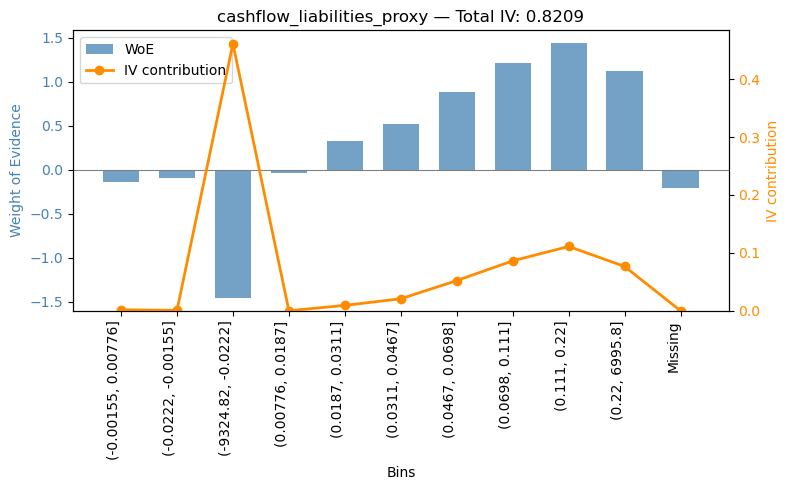

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-9324.82, -0.0222]",47522,2736,10.00%,5.76%,41.14%,5.76%,41.14%,4.116
1,"(-0.0222, -0.00155]",47521,729,10.00%,1.53%,10.96%,3.65%,52.11%,2.606
2,"(-0.00155, 0.00776]",47521,759,10.00%,1.60%,11.41%,2.96%,63.52%,2.118
3,"(0.00776, 0.0187]",47522,692,10.00%,1.46%,10.41%,2.59%,73.92%,1.849
4,"(0.0187, 0.0311]",47521,479,10.00%,1.01%,7.20%,2.27%,81.13%,1.623
5,"(0.0311, 0.0467]",47521,399,10.00%,0.84%,6.00%,2.03%,87.13%,1.453
6,"(0.0467, 0.0698]",47522,277,10.00%,0.58%,4.17%,1.83%,91.29%,1.305
7,"(0.0698, 0.111]",47521,199,10.00%,0.42%,2.99%,1.65%,94.29%,1.179
8,"(0.111, 0.22]",47521,159,10.00%,0.33%,2.39%,1.50%,96.68%,1.075
9,"(0.22, 6995.8]",47522,218,10.00%,0.46%,3.28%,1.40%,99.95%,1.000


Feature: net_profit_assets, IV: 0.778038412590097


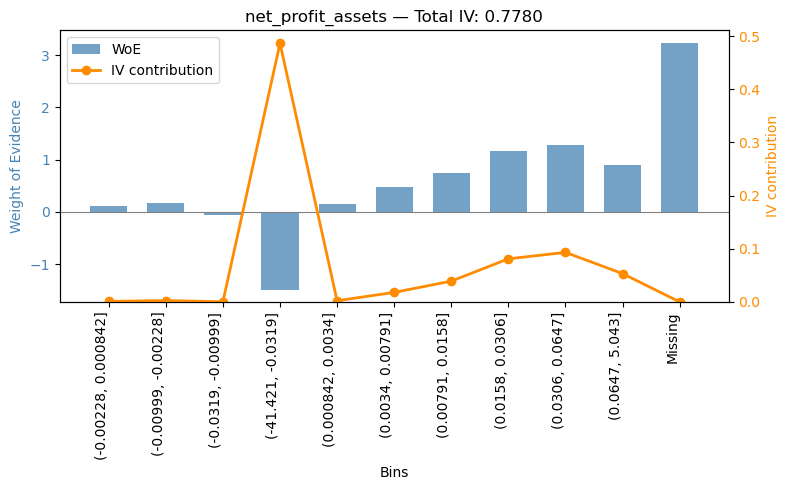

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-41.421, -0.0319]",47538,2809,10.00%,5.91%,42.24%,5.91%,42.24%,4.224
1,"(-0.0319, -0.00999]",47537,709,10.00%,1.49%,10.66%,3.70%,52.90%,2.645
2,"(-0.00999, -0.00228]",47537,562,10.00%,1.18%,8.45%,2.86%,61.35%,2.045
3,"(-0.00228, 0.000842]",47537,597,10.00%,1.26%,8.98%,2.46%,70.33%,1.758
4,"(0.000842, 0.0034]",47537,568,10.00%,1.19%,8.54%,2.21%,78.87%,1.578
5,"(0.0034, 0.00791]",47537,416,10.00%,0.88%,6.26%,1.98%,85.13%,1.419
6,"(0.00791, 0.0158]",47537,319,10.00%,0.67%,4.80%,1.80%,89.92%,1.285
7,"(0.0158, 0.0306]",47537,209,10.00%,0.44%,3.14%,1.63%,93.07%,1.163
8,"(0.0306, 0.0647]",47537,187,10.00%,0.39%,2.81%,1.49%,95.88%,1.065
9,"(0.0647, 5.043]",47537,274,10.00%,0.58%,4.12%,1.40%,100.00%,1.000


Feature: operating_cashflow_assets, IV: 0.7747245116514192


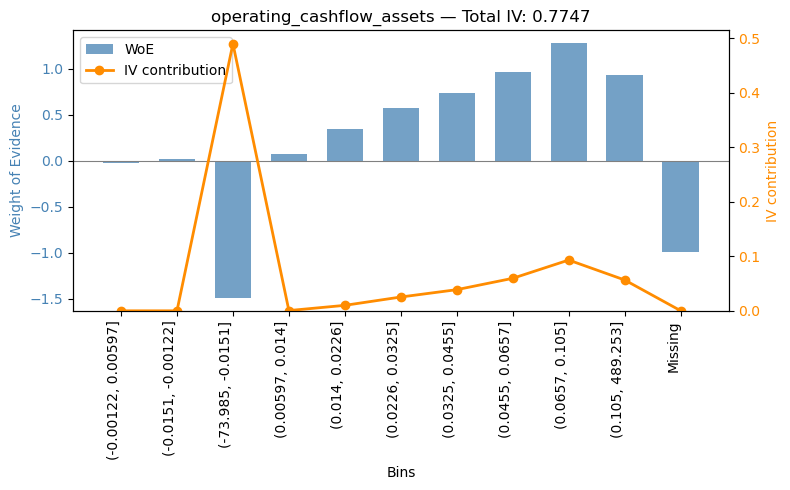

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-73.985, -0.0151]",47531,2819,10.00%,5.93%,42.39%,5.93%,42.39%,4.240
1,"(-0.0151, -0.00122]",47531,650,10.00%,1.37%,9.77%,3.65%,52.17%,2.609
2,"(-0.00122, 0.00597]",47530,682,10.00%,1.43%,10.26%,2.91%,62.42%,2.081
3,"(0.00597, 0.014]",47531,618,10.00%,1.30%,9.29%,2.51%,71.71%,1.793
4,"(0.014, 0.0226]",47531,473,10.00%,1.00%,7.11%,2.21%,78.83%,1.577
5,"(0.0226, 0.0325]",47530,376,10.00%,0.79%,5.65%,1.97%,84.48%,1.408
6,"(0.0325, 0.0455]",47531,320,10.00%,0.67%,4.81%,1.78%,89.29%,1.276
7,"(0.0455, 0.0657]",47530,257,10.00%,0.54%,3.86%,1.63%,93.16%,1.165
8,"(0.0657, 0.105]",47531,187,10.00%,0.39%,2.81%,1.49%,95.97%,1.067
9,"(0.105, 489.253]",47531,265,10.00%,0.56%,3.98%,1.40%,99.95%,1.000


Feature: liabilities_assets_proxy, IV: 0.6212417927236698


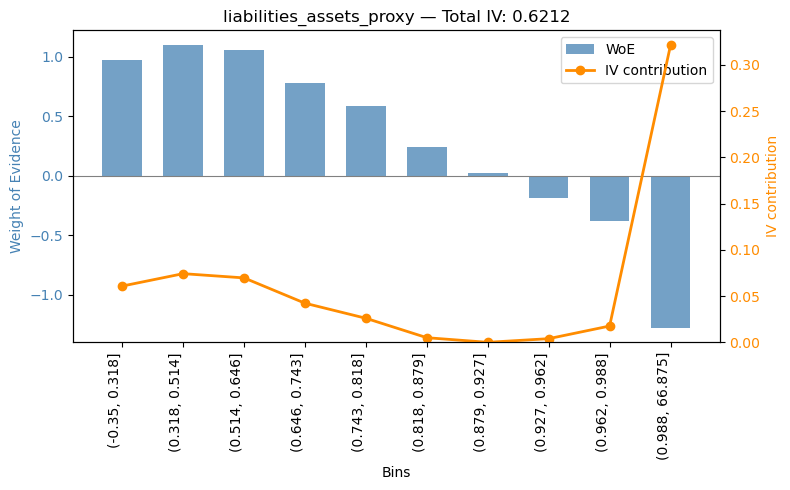

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-0.35, 0.318]",47539,254,10.00%,0.53%,3.82%,0.53%,3.82%,0.382
1,"(0.318, 0.514]",47539,223,10.00%,0.47%,3.35%,0.50%,7.17%,0.359
2,"(0.514, 0.646]",47539,233,10.00%,0.49%,3.50%,0.50%,10.68%,0.356
3,"(0.646, 0.743]",47539,308,10.00%,0.65%,4.63%,0.54%,15.31%,0.383
4,"(0.743, 0.818]",47539,373,10.00%,0.78%,5.61%,0.59%,20.92%,0.418
5,"(0.818, 0.879]",47538,526,10.00%,1.11%,7.91%,0.67%,28.83%,0.480
6,"(0.879, 0.927]",47539,653,10.00%,1.37%,9.82%,0.77%,38.65%,0.552
7,"(0.927, 0.962]",47539,802,10.00%,1.69%,12.06%,0.89%,50.71%,0.634
8,"(0.962, 0.988]",47539,968,10.00%,2.04%,14.56%,1.01%,65.26%,0.725
9,"(0.988, 66.875]",47539,2310,10.00%,4.86%,34.74%,1.40%,100.00%,1.000


Feature: equity_assets, IV: 0.6212405592543003


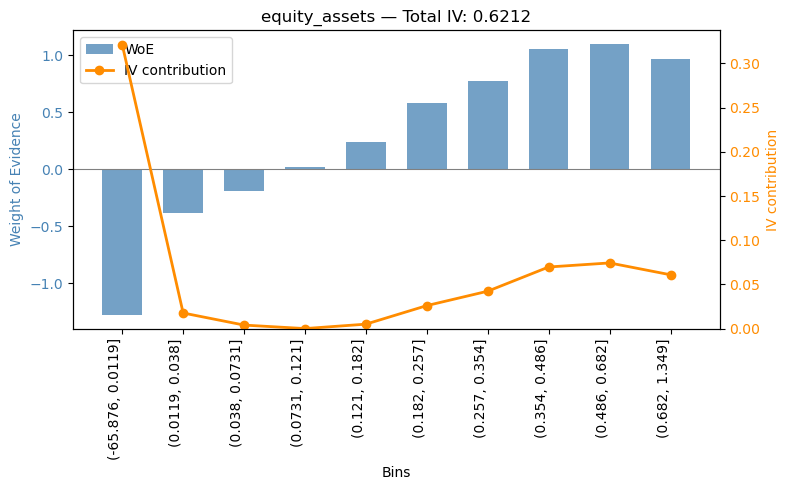

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-65.876, 0.0119]",47539,2310,10.00%,4.86%,34.74%,4.86%,34.74%,3.474
1,"(0.0119, 0.038]",47539,968,10.00%,2.04%,14.56%,3.45%,49.29%,2.465
2,"(0.038, 0.0731]",47539,802,10.00%,1.69%,12.06%,2.86%,61.35%,2.045
3,"(0.0731, 0.121]",47539,653,10.00%,1.37%,9.82%,2.49%,71.17%,1.779
4,"(0.121, 0.182]",47539,526,10.00%,1.11%,7.91%,2.21%,79.08%,1.582
5,"(0.182, 0.257]",47538,373,10.00%,0.78%,5.61%,1.97%,84.69%,1.412
6,"(0.257, 0.354]",47539,308,10.00%,0.65%,4.63%,1.79%,89.32%,1.276
7,"(0.354, 0.486]",47539,233,10.00%,0.49%,3.50%,1.62%,92.83%,1.160
8,"(0.486, 0.682]",47539,223,10.00%,0.47%,3.35%,1.49%,96.18%,1.069
9,"(0.682, 1.349]",47539,254,10.00%,0.53%,3.82%,1.40%,100.00%,1.000


Feature: operating_profit_assets, IV: 0.615308446499006


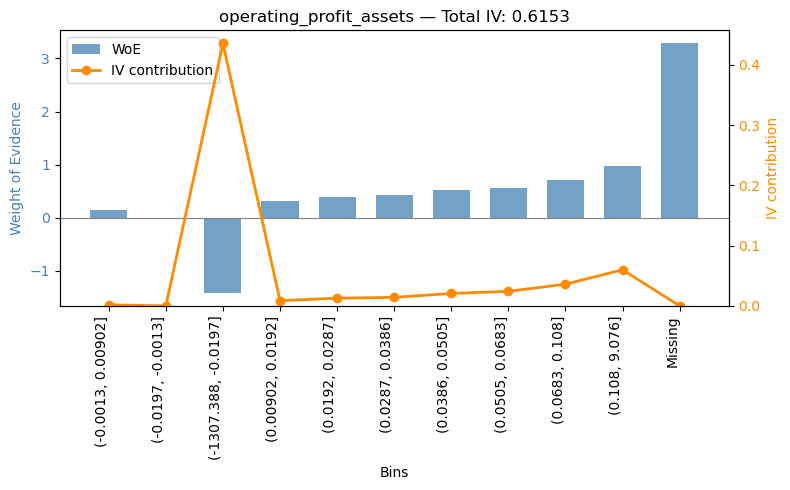

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-1307.388, -0.0197]",47537,2662,10.00%,5.60%,40.03%,5.60%,40.03%,4.003
1,"(-0.0197, -0.0013]",47537,671,10.00%,1.41%,10.09%,3.51%,50.12%,2.506
2,"(-0.0013, 0.00902]",47537,575,10.00%,1.21%,8.65%,2.74%,58.77%,1.959
3,"(0.00902, 0.0192]",47537,485,10.00%,1.02%,7.29%,2.31%,66.06%,1.652
4,"(0.0192, 0.0287]",47537,450,10.00%,0.95%,6.77%,2.04%,72.83%,1.457
5,"(0.0287, 0.0386]",47537,440,10.00%,0.93%,6.62%,1.85%,79.44%,1.324
6,"(0.0386, 0.0505]",47537,400,10.00%,0.84%,6.02%,1.71%,85.46%,1.221
7,"(0.0505, 0.0683]",47537,381,10.00%,0.80%,5.73%,1.59%,91.19%,1.140
8,"(0.0683, 0.108]",47537,330,10.00%,0.69%,4.96%,1.49%,96.15%,1.068
9,"(0.108, 9.076]",47537,256,10.00%,0.54%,3.85%,1.40%,100.00%,1.000


Feature: interest_coverage_proxy, IV: 0.5555535041064982


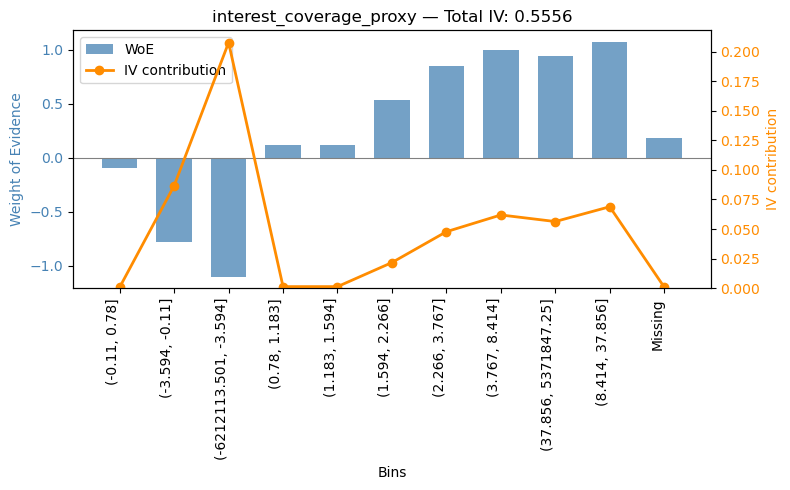

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-6212113.501, -3.594]",45964,1880,9.67%,4.09%,28.27%,4.09%,28.27%,2.924
1,"(-3.594, -0.11]",45964,1375,9.67%,2.99%,20.68%,3.54%,48.95%,2.531
2,"(-0.11, 0.78]",45963,705,9.67%,1.53%,10.60%,2.87%,59.55%,2.053
3,"(0.78, 1.183]",45964,570,9.67%,1.24%,8.57%,2.46%,68.12%,1.761
4,"(1.183, 1.594]",45964,570,9.67%,1.24%,8.57%,2.22%,76.69%,1.586
5,"(1.594, 2.266]",45963,378,9.67%,0.82%,5.68%,1.99%,82.38%,1.420
6,"(2.266, 3.767]",45964,276,9.67%,0.60%,4.15%,1.79%,86.53%,1.278
7,"(3.767, 8.414]",45963,238,9.67%,0.52%,3.58%,1.63%,90.11%,1.165
8,"(8.414, 37.856]",45964,222,9.67%,0.48%,3.34%,1.50%,93.44%,1.074
9,"(37.856, 5371847.25]",45964,252,9.67%,0.55%,3.79%,1.41%,97.23%,1.006


Feature: operating_margin, IV: 0.5070978756324289


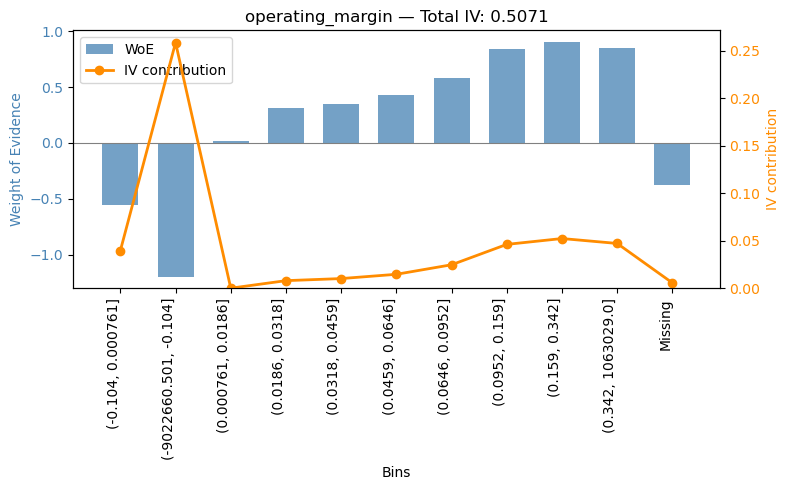

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-9022660.501, -0.104]",45979,2061,9.67%,4.48%,30.99%,4.48%,30.99%,3.204
1,"(-0.104, 0.000761]",45979,1110,9.67%,2.41%,16.69%,3.45%,47.68%,2.465
2,"(0.000761, 0.0186]",45978,630,9.67%,1.37%,9.47%,2.76%,57.16%,1.970
3,"(0.0186, 0.0318]",45979,474,9.67%,1.03%,7.13%,2.32%,64.29%,1.662
4,"(0.0318, 0.0459]",45979,454,9.67%,0.99%,6.83%,2.06%,71.11%,1.471
5,"(0.0459, 0.0646]",45978,420,9.67%,0.91%,6.32%,1.87%,77.43%,1.334
6,"(0.0646, 0.0952]",45979,363,9.67%,0.79%,5.46%,1.71%,82.89%,1.224
7,"(0.0952, 0.159]",45978,281,9.67%,0.61%,4.23%,1.57%,87.11%,1.126
8,"(0.159, 0.342]",45979,263,9.67%,0.57%,3.95%,1.46%,91.07%,1.046
9,"(0.342, 1063029.0]",45979,278,9.67%,0.60%,4.18%,1.38%,95.25%,0.985


In [13]:
for feats in suspicious_features['features']:
    print(f'Feature: {feats}, IV: {suspicious_features.query("features == @feats")["iv_train"].values[0]}')
    # display(iv_df.query('features == @feats')['iv_train_df'].values[0])
    fig, axes = plot_woe_iv(iv_df.query('features == @feats')['iv_train_df'].values[0], feats, figsize=(8, 5))
    plt.show()
    display(precision_recall_by_bin(features.query('data_type == "train"'), feats))